# Adel, 1: your first wheat plant

**What you will learn:** grow a wheat plant with Adel's default parameters, read its results (a table per day, a table
per organ), and draw it in 3D.

**You need:** basic Python (running a cell, calling a function). No knowledge of plant models or of metafspm is
assumed. **Run time:** a few seconds.

This is the first of six user tutorials:

| | notebook | what you do |
|---|---|---|
| 1 | `01_first_run.ipynb` | grow a wheat plant with the default parameters, read and plot its results |
| 2 | `02_change_a_parameter.ipynb` | find the parameters, change one, describe another plant |
| 3 | `03_combine_parameters.ipynb` | explore two parameters together |
| 4 | `04_sensitivity_analysis.ipynb` | find which parameters matter most |
| 5 | `05_experimental_data.ipynb` | use measured inputs, compare with observations, fit a parameter |
| 6 | `06_with_other_models.ipynb` | light the canopy with a light model |

Developers who want to understand how the model is written and ported will find a second series in
`../developer/`, best read after this one.

## What Adel represents

**Adel** (Fournier et al., 2003) builds the 3D shape of wheat plants as they grow: where each leaf, sheath and stem
piece is, how long and wide it is, and its shape. Light models then use this 3D plant, for instance to compute how much
light each leaf intercepts.

A wheat plant is made of repeated units called **phytomers**. Each phytomer has:
- an **internode**, a piece of stem;
- a **sheath**, which wraps around the stem;
- a **blade**, the flat part of the leaf.

The phytomers pile up along an **axis**. The first axis is the **main stem**. The side shoots that grow from its base
are **tillers** (T1, T2, ...), each an axis of its own.

Plants develop with temperature rather than with days. Development is counted in **thermal time**: each day adds its
mean temperature (above a base of 0 °C here), in **degree-days** (°Cd). A day at 15 °C adds 15 °Cd. A new leaf appears
on an axis every **phyllochron** (about 89 °Cd here). The **Haun stage** counts the leaves appeared on the main stem,
with fractions for the leaf growing. Old leaves turn yellow and dry: this is **senescence**.

*Reference:* Fournier C., Andrieu B., Ljutovac S., Saint-Jean S. (2003). ADEL-wheat: a 3D architectural model of
wheat development. *Plant Growth Modeling and Applications*, 54–63.

*A word on metafspm:* this package is written with metafspm, a framework in which plant models are built as
**components** that can be combined (a shoot model, a root model, a light model...). You do not need to know it to use
Adel; the last section of this tutorial says a little more.

## 1. Grow a plant

`simulate` grows one wheat plant, one step per day. With no argument other than the duration, it uses the model's
**default parameters**: Adel's sample plant (a main stem of 12 leaves and 4 tillers), at 15 °C every day.

In [1]:
import matplotlib.pyplot as plt

from openalea.adel.simulation import simulate

result = simulate(days=80)

## 2. The summary: one row per day

`result.summary` is a table (a pandas DataFrame) with one row per day:

| column | meaning | unit |
|---|---|---|
| `day` | days since sowing | days |
| `thermal_time` | thermal time since sowing | °Cd |
| `haun_stage` | leaves appeared on the main stem (with fractions) | – |
| `visible_leaves` | blades of the main stem out of the sheaths | – |
| `tillers` | tillers appeared | – |
| `height` | height of the tallest stem (internodes and sheaths) above the soil | m |
| `green_leaf_area` | area of the green blades (one face) | m² |
| `senesced_leaf_area` | area of the senesced (yellow) blades | m² |

The model computes in the international units: metres, square metres. Below, every 10th row:

In [2]:
result.summary.iloc[::10]

,day,thermal_time,haun_stage,visible_leaves,tillers,height,green_leaf_area,senesced_leaf_area
0,0.0,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.000000
10,10.0,150.0,1.444635,2.0,0.0,0.000000,0.000339,0.000000
20,20.0,300.0,3.131544,4.0,2.0,0.013406,0.000975,0.000000
30,30.0,450.0,4.818454,5.0,4.0,0.023240,0.002034,0.000000
40,40.0,600.0,6.505363,7.0,4.0,0.025591,0.003194,0.000172
50,50.0,750.0,8.192273,9.0,4.0,0.051068,0.004189,0.000814
60,60.0,900.0,9.879182,10.0,4.0,0.077028,0.005592,0.001827
70,70.0,1050.0,11.566092,11.0,4.0,0.139674,0.007268,0.003326
80,80.0,1200.0,12.000000,12.0,4.0,0.247053,0.005514,0.005261


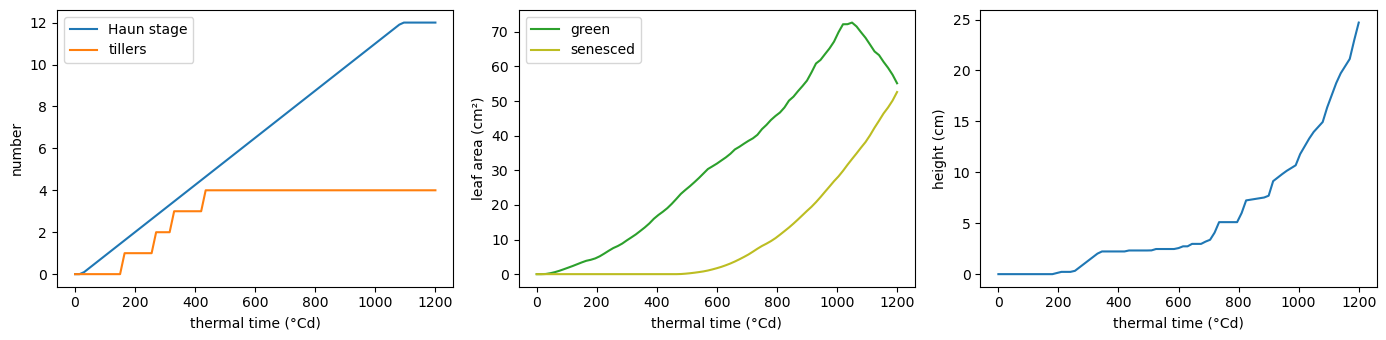

In [3]:
summary = result.summary
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
axes[0].plot(summary["thermal_time"], summary["haun_stage"], label="Haun stage")
axes[0].plot(summary["thermal_time"], summary["tillers"], label="tillers")
axes[0].set_ylabel("number"); axes[0].legend()
axes[1].plot(summary["thermal_time"], summary["green_leaf_area"] * 1e4, color="tab:green", label="green")
axes[1].plot(summary["thermal_time"], summary["senesced_leaf_area"] * 1e4, color="tab:olive", label="senesced")
axes[1].set_ylabel("leaf area (cm²)"); axes[1].legend()
axes[2].plot(summary["thermal_time"], summary["height"] * 100)
axes[2].set_ylabel("height (cm)")
for ax in axes:
    ax.set_xlabel("thermal time (°Cd)")
plt.tight_layout()

**Reading the curves.**

- The **Haun stage** rises steadily: one leaf every phyllochron (about 89 °Cd), until the 12th and last leaf of the
  main stem, the flag leaf.
- The four **tillers** appear early, before 450 °Cd.
- The **green leaf area** grows as leaves appear on the main stem and on the tillers. From about 500 °Cd the oldest
  leaves senesce. At the end, as many leaves senesce as appear, and the green area falls.
- The **height** stays low while the stem is made of sheaths only. It rises late, once the internodes elongate: this
  is stem elongation, before heading.

## 3. Draw the plant

`result.draw()` shows the plant in 3D. Green elements are green, senesced ones straw-coloured. The plant is sown 2 cm
deep, so its base is below the soil surface (z = 0).

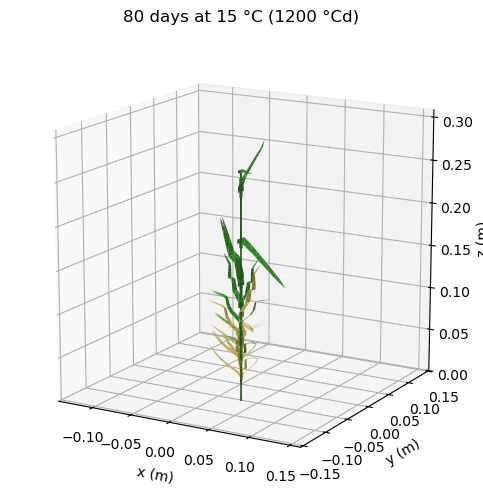

In [4]:
result.draw()
plt.title("80 days at 15 °C (1200 °Cd)");

## 4. The axes and the organs

`result.axes()` lists the axes: the main stem `MS` and the tillers. A tiller has fewer leaves than the main stem.

In [5]:
result.axes()

,plant,axis,phytomers,haun_stage,final_leaf_number
0,0,MS,12,12.0,12
1,0,T1,9,9.0,9
2,0,T2,8,8.0,8
3,0,T3,7,7.0,7
4,0,T4,6,6.0,6


`result.organs()` lists every organ, one row each:

- `axis` and `rank`: where it is, its rank from the bottom of its axis;
- `organ`: internode, sheath or blade;
- `length`, `visible_length` (out of the sheaths) and `senesced_length` (m), and its visible `area` (m²).

The rows are ordinary pandas data, so they can be filtered, summed or grouped. Here are the main stem's blades:

In [6]:
organs = result.organs()
main_stem_blades = organs[(organs["axis"] == "MS") & (organs["organ"] == "blade")]
main_stem_blades

,plant,axis,organ,rank,length,visible_length,senesced_length,area
2,0,MS,blade,1,0.097332,0.097332,0.097332,0.000352
5,0,MS,blade,2,0.082562,0.060278,0.082562,0.000205
11,0,MS,blade,3,0.068224,0.044877,0.068224,0.000143
20,0,MS,blade,4,0.065023,0.040082,0.065023,0.000126
32,0,MS,blade,5,0.074524,0.046646,0.074524,0.000168
47,0,MS,blade,6,0.092659,0.057629,0.092659,0.000262
62,0,MS,blade,7,0.118811,0.069036,0.089227,0.000400
77,0,MS,blade,8,0.149547,0.078423,0.062461,0.000570
92,0,MS,blade,9,0.175081,0.082759,0.014765,0.000639
107,0,MS,blade,10,0.189396,0.083193,0.000000,0.000717


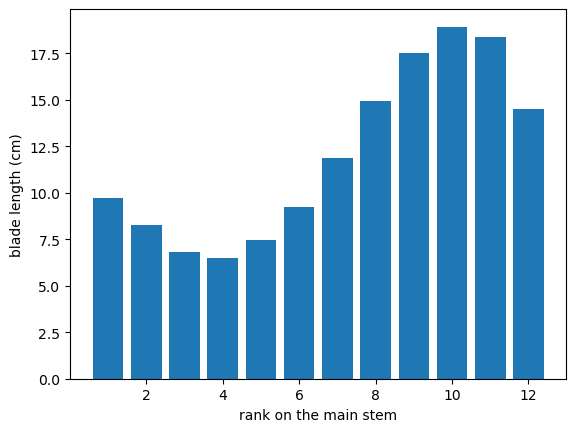

In [7]:
plt.bar(main_stem_blades["rank"], main_stem_blades["length"] * 100)
plt.xlabel("rank on the main stem"); plt.ylabel("blade length (cm)");

## Saving a run

With `outputs=`, `simulate` also writes the run in a folder, to keep it, compare it with others later, or open it in
another program:

- `run.json`: how the run went (finished, or the error that stopped it), when, and how long it took;
- `scenario.json`: everything the run was made with (the parameters, the plants), to run it again;
- `summary.csv`: the summary above;
- `Plant/ScenarioShoot/summaries.csv`: every quantity of the plant, summed or averaged over its organs, day by day;
- `frames/`: the whole plant every 10 days, in the fspm-TF format that ParaView (with fspm-TF's reader) and other
  plant modelling platforms open.

In [8]:
import json
import os

import pandas as pd

saved = simulate(days=80, outputs="outputs/first_run")
print(sorted(os.listdir("outputs/first_run")))
with open("outputs/first_run/run.json") as file:
    run = json.load(file)
print(run["status"], "in", round(run["wall_time"], 1), "s")
pd.read_csv("outputs/first_run/summary.csv").tail(3)

['Plant', 'frames', 'run.json', 'scenario.json', 'summary.csv']
finished in 1.5 s


,day,thermal_time,haun_stage,visible_leaves,tillers,height,green_leaf_area,senesced_leaf_area
78,78.0,1170.0,12.0,12.0,4.0,0.211335,0.005961,0.004815
79,79.0,1185.0,12.0,12.0,4.0,0.229842,0.005761,0.005015
80,80.0,1200.0,12.0,12.0,4.0,0.247053,0.005514,0.005261


## Try it yourself

1. Grow the plant for 40 days only. How many leaves does the main stem have? How tall is it?
2. Grow it at 20 °C instead of 15 °C (`simulate(days=80, temperature=20.)`). After how many days does the Haun stage
   reach 12?
3. With `organs`, find the total area of each tiller's blades (`groupby("axis")`).

**Next:** `02_change_a_parameter.ipynb`, to change the plant's characteristics.

## Behind `simulate`: how the model is meant to be used

`simulate` is a convenience for these tutorials, not the model itself. The model is the component `ShootArchitecture`
(in `openalea.adel.architecture`). In metafspm a component is not run on its own. Its intended use has three layers:

1. **The component**, `ShootArchitecture`, builds the plant: its axes, phytomers and organs, their shapes and their 3D
   positions. It does not decide how fast the organs grow: other components give it their lengths.
2. **A plant model** (a metafspm `CompositeModel`) gathers the components of a plant and **couples** them, connecting
   what one computes to what another needs. Here, the plant model `ScenarioShoot` couples `ShootArchitecture` with
   `ScenarioDevelopment` (in `openalea.adel.development`), a simple scenario that gives the organs' lengths from the
   thermal time. A growth model, a light model or a root model could be coupled the same way.
3. **A scene** (a metafspm `Scene`) plants one or several plants of that model at given positions, possibly with an
   environment (a soil, the light). It advances them all, step by step.

`simulate` builds the simplest case: one plant of `ScenarioShoot` in a scene, its thermal time given each day from the
temperature (a time series, metafspm's forcings), its results recorded by metafspm's `SceneRecorder` (the summary,
and the files of `outputs=`). To use Adel with other models, or to build your own plant
models and scenes, you write the plant model and the scene yourself. The developer tutorial
`../developer/01_shoot_architecture_in_metafspm.ipynb` shows how: the component's declarations and steps, the coupling
contract, a scene of 20 plants. Its overview, `../developer/00_overview.ipynb`, describes the package. metafspm's
beginner page, ["metafspm in five minutes"](https://github.com/openalea/metafspm/blob/data_structure_api/docs/five_minutes.md), explains components, plant models and scenes in
plain words.